# Rabbits and foxes, with `solve_ivp`

**CHME 5137, Lecture 8, Tuesday October 6, 2026.** Started in class, finished for
homework.

*Revised for 2026 by Claude Code (Claude Opus 5.5) from the Lecture 3 notebook, and
checked by Prof. West. The problem is from Chapter 1 of H. Scott Fogler's
"Essentials of Chemical Reaction Engineering". The tasks are new.*

---

There are initially 400 rabbits and 200 foxes on a farm. (Or two cell types in a
96-well plate, if you prefer.) The populations obey

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

* Growth of rabbits, $k_1 = 0.015$ day$^{-1}$
* Death of rabbits being eaten by foxes, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$
* Growth of foxes after eating rabbits, $k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$
* Death of foxes, $k_4 = 0.04$ day$^{-1}$

In Lecture 3 you solved this with Euler's method. You found that the fox peaks,
which should all be the same height, crept upwards. At a step of 0.1 days (12,000
steps for 1200 days) they went 2816, 2854, 2893. At 0.005 days (240,000 steps) they
went 2804.5, 2806.4, 2808.2. Today: how well does a library do, and at what cost?

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Use the in-class notebook**, `solve-ivp-intro.ipynb`, for the syntax.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0

## 1. Solve it, and plot it

Write a function `dydt(t, y)` that returns $[dR/dt,\ dF/dt]$. Then call
`solve_ivp` with its **default** settings for 600 days.

Print `sol.success`, `sol.nfev` and `len(sol.t)`. Then plot both populations
against time, with axis labels and a legend.

sol.success: True
sol.nfev: 242
len(sol.t): 32


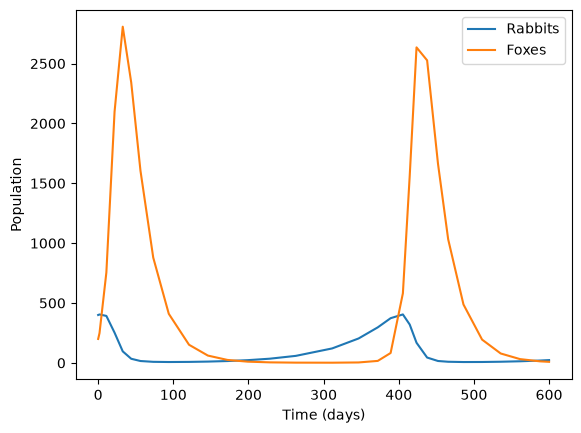

In [19]:
def dydt(t, y):
    R, F = y
    dRdt = k1 * R - k2 * R * F
    dFdt = k3 * R * F - k4 * F
    return [dRdt, dFdt]


sol = solve_ivp(dydt, (0, 600), y0)

print("sol.success:", sol.success)
print("sol.nfev:", sol.nfev)
print("len(sol.t):", len(sol.t))

plt.plot(sol.t, sol.y[0], label="Rabbits")
plt.plot(sol.t, sol.y[1], label="Foxes")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.legend()
plt.show()

Your plot is probably jagged. Why? Fix it in two ways: with `t_eval`, and with
`dense_output=True`. Does either one change `sol.nfev`?

t_eval nfev: 242


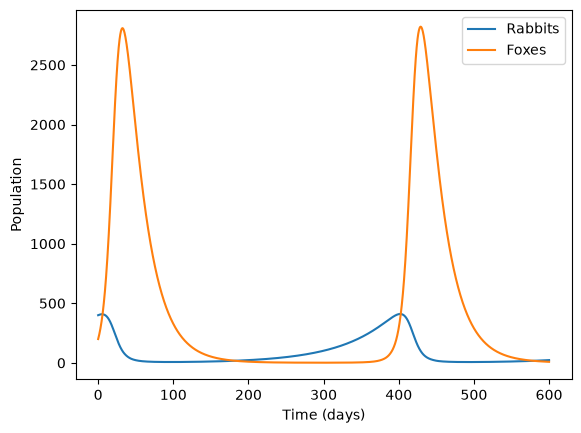

In [20]:
times = np.linspace(0, 600, 2000)

sol_eval = solve_ivp(dydt, (0, 600), y0, t_eval=times)

print("t_eval nfev:", sol_eval.nfev)

plt.plot(sol_eval.t, sol_eval.y[0], label="Rabbits")
plt.plot(sol_eval.t, sol_eval.y[1], label="Foxes")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.legend()
plt.show()

dense_output nfev: 242


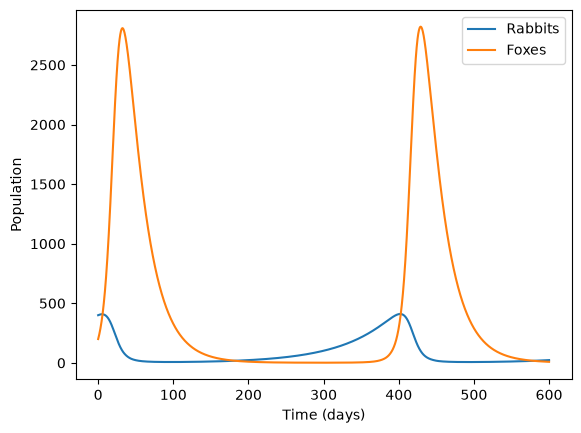

In [21]:
sol_dense = solve_ivp(dydt, (0, 600), y0, dense_output=True)
populations = sol_dense.sol(times)

print("dense_output nfev:", sol_dense.nfev)

plt.plot(times, populations[0], label="Rabbits")
plt.plot(times, populations[1], label="Foxes")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.legend()
plt.show()

*Answer:*
The original plot is jagged because it connects only 32 returned time points with straight lines. Using t_eval requests values at 2,000 specified times. Using dense_output=True creates a continuous interpolating solution that I can evaluate at those same times.

Both approaches make the plots smoother. Neither changes nfev:
it remains 242 for this default RK45 solve. Both use interpolation within the solver's adaptive steps rather than forcing smaller steps. A smoother plot does not necessarily mean a more accurate solution.

## 2. The phase portrait

Solve to 1200 days, three full cycles, and plot foxes against rabbits. The exact
solution is a closed loop, traced over and over. Is yours?

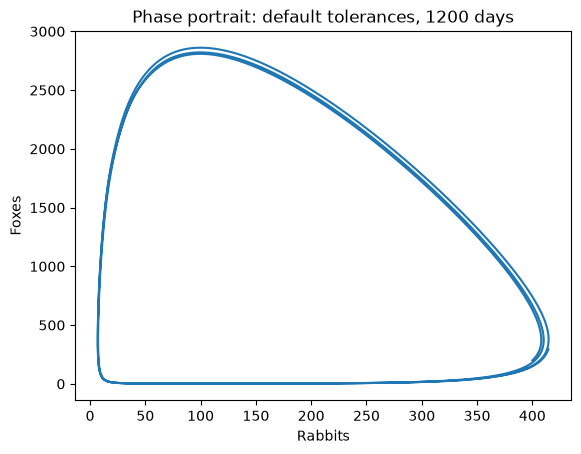

In [22]:
phase = solve_ivp(dydt, (0, 1200), y0, dense_output=True)
phase_times = np.linspace(0, 1200, 6000)
R, F = phase.sol(phase_times)
plt.figure()
plt.plot(R, F)
plt.xlabel("Rabbits")
plt.ylabel("Foxes")
plt.title("Phase portrait: default tolerances, 1200 days")
plt.show()

*Answer:*

Yes, the phase portrait is a smooth closed loop when the populations are plotted as foxes vs. rabbits over 1200 days.
The solver traces three nearly identical predator–prey cycles, which is the expected behavior for this nonlinear system.
Any tiny gap between start and end of the orbit is just numerical error from the adaptive solver tolerance, not a real drift in the model.

## 3. The height of each fox peak, using events

Searching `sol.y` for the largest value gives you the largest value **at the times
the solver happened to stop**, which won't be exactly at the peak. `solve_ivp` can
find the exact moment instead, with an *event*: a function `g(t, y)` that it
watches. It reports every time `g` passes through zero.

The foxes peak when $dF/dt$ changes from positive to negative. Since
$dF/dt = F(k_3 R - k_4)$ and $F > 0$, that happens when $k_3 R - k_4$ goes from
positive to negative. So:

```python
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1   # only count it when g is decreasing through zero

sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
sol.t_events[0]          # the times of the peaks
sol.y_events[0]          # the [R, F] values at each one
```

Print the time and height of each fox peak, with the default tolerances. Compare
with the Euler peaks above. How many function evaluations did it take, compared
with Euler's 12,000 or 240,000 steps?

In [ ]:
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1

peaks_default = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
for t, (R, F) in zip(peaks_default.t_events[0], peaks_default.y_events[0]):
    print(f"Time: {t:.6f} days; fox peak: {F:.9f}")
print("nfev:", peaks_default.nfev)
print("Peak drift:", np.ptp(peaks_default.y_events[0][:, 1]))

*Answer:*
With default tolerances, the fox peaks occur at approximately 32.320341, 429.101960, and 828.515944 days. Their heights are 2808.625454, 2820.996973, and 2860.878362 foxes. The last minus first peak is about 52.25 foxes, so the default solution still drifts noticeably.
Euler with a 0.1-day step gave peaks 2816, 2854, and 2893 (about 77 foxes of drift). Euler with a 0.005-day step gave 2804.5, 2806.4, and 2808.2 (about 3.7 foxes of drift). Default RK45 is better than coarse Euler on this drift measure but worse than fine Euler. It uses only 440 right-hand-side evaluations, compared with approximately 12,000 or 240,000 Euler evaluations. Events locate peaks using the solver's interpolated approximation; they do not make the peak values mathematically exact.

## 4. Required accuracy: `rtol`

The true peaks are all the same height. So the *drift*, last peak minus first, is a
measure of the error, and we don't need the exact answer to find it.

Loop over `rtol` from `1e-3` to `1e-10`, keeping `atol = 1e-8`. For each value
record the drift and `sol.nfev`. Then make two log-log plots: |drift| against
`rtol`, and |drift| against `nfev`. The second is called a *work–precision
diagram*.

- How tight must `rtol` be for the peaks to agree to within one fox? To within
  0.01 of a fox?
- What is the height of the fox peak, to as many significant figures as you can
  justify? How do you know?
- Euler with 240,000 steps had a drift of 3.7 foxes. How many function evaluations
  does `solve_ivp` need to do better than that?

In [ ]:
rtols = 10.0 ** (-np.arange(3, 11))
drifts, work, peak_heights = [], [], []
print("rtol       last - first       nfev       first peak")
for tolerance in rtols:
    result = solve_ivp(dydt, (0, 1200), y0, events=fox_peak,
                       rtol=tolerance, atol=1e-8)
    heights = result.y_events[0][:, 1]
    drift = heights[-1] - heights[0]
    drifts.append(drift)
    work.append(result.nfev)
    peak_heights.append(heights)
    print(f"{tolerance:.0e}    {drift: .9e}    {result.nfev:5d}    {heights[0]:.10f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(rtols, np.abs(drifts), "o-")
axes[0].set_xlabel("rtol")
axes[0].set_ylabel("Absolute peak drift (foxes)")
axes[1].loglog(work, np.abs(drifts), "o-")
axes[1].set_xlabel("Function evaluations (nfev)")
axes[1].set_ylabel("Absolute peak drift (foxes)")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

*Answer:*

In [ ]:
Among the tested tolerances with atol = 1e-8, rtol = 1e-5 is the loosest value for which the first and last peaks agree within one fox (drift approximately 0.08146). For agreement within 0.01 fox, rtol = 1e-7 is needed (absolute drift approximately 0.000417). The tested value 1e-6 narrowly misses that target, with drift about 0.010269.
The peak height is approximately 2803.8701 foxes (eight significant figures). The first peaks at rtol = 1e-9 and 1e-10 are 2803.8700989 and 2803.8700961, which both round to this value, and the tightest-run peak drift is less than 1e-6 fox. This convergence supports the quoted digits, although it is not a rigorous error bound. Drift is not strictly monotonic at the tightest settings: rounding, interpolation, error cancellation, and the fixed absolute tolerance can influence it.
RK45 already beats Euler's 3.7-fox drift at rtol = 1e-4 with 656 evaluations and a drift of approximately 1.60 foxes, compared with Euler's 240,000 steps. The work–precision plot shows the broad tradeoff: tighter tolerances cost more evaluations and generally reduce drift.

## 5. `atol`, and how few foxes is too few?

What is the **smallest** number of foxes during the cycle, and of rabbits? (Use
`dense_output=True` and a fine grid of times, or another event.)

Now someone argues: "A fraction of a fox is meaningless, so I'll set `atol = 1`."
Try it, with `rtol = 1e-6`. Then try `atol = 10`. What happens to the peaks? Explain
why, using the formula for the error tolerance, $\text{atol} + \text{rtol}\,|y|$.

And about the model itself: what does a population of under two foxes mean? Would a
real population survive that trough? (Lecture 10, kinetic Monte Carlo, is one way
to model that properly.)

In [ ]:
def rabbit_minimum(t, y):
    return k1 - k2 * y[1]

def fox_minimum(t, y):
    return k3 * y[0] - k4

rabbit_minimum.direction = 1
fox_minimum.direction = 1
minimum_solution = solve_ivp(
    dydt, (0, 1200), y0, rtol=1e-10, atol=1e-12,
    events=[rabbit_minimum, fox_minimum])
print("Rabbit minima:", minimum_solution.y_events[0][:, 0])
print("Fox minima:", minimum_solution.y_events[1][:, 1])

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for absolute_tolerance in [1e-8, 1, 10]:
    result = solve_ivp(dydt, (0, 1200), y0, rtol=1e-6,
                       atol=absolute_tolerance, events=fox_peak, dense_output=True)
    print(f"atol={absolute_tolerance}: success={result.success}, "
          f"nfev={result.nfev}, peak times={result.t_events[0]}, "
          f"peak heights={result.y_events[0][:, 1]}")
    grid = np.linspace(0, result.t[-1], 6000)
    values = result.sol(grid)
    for ax, population in zip(axes, values):
        ax.plot(grid, population, label=f"atol={absolute_tolerance}")
axes[0].set_ylabel("Rabbits")
axes[1].set_ylabel("Foxes")
axes[1].set_xlabel("Time (days)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

*Answer:*
Using upward zero crossings of the derivatives with tight tolerances, the minimum populations are approximately 7.42607 rabbits and 1.59364 foxes. These minima repeat across the three cycles.
The solver scales its local error estimate using atol + rtol*abs(y). Near the fox trough, the relative term is only about 1.6e-6 fox. An atol of 1 or 10 therefore dominates the tolerance scale and permits errors large relative to the small population. Those errors alter later growth and peaks. The tolerance is a local numerical scale, not a guarantee of total global error.
A fractional population is a continuous model value, which can be interpreted as a population density or average rather than a literal fraction of an animal. A real population of one or two foxes could become extinct through random deaths or fail to reproduce. Survival is not guaranteed; this deterministic model cannot represent discrete extinction and always permits recovery from positive populations. A stochastic population model would address that limitation.

## 6. Which method?

At `rtol = 1e-8, atol = 1e-8`, compare `method=` `"RK45"`, `"DOP853"`, `"LSODA"`,
`"BDF"` and `"Radau"`: drift and `nfev` for each. Which is cheapest for this
problem? Is this problem stiff? How can you tell?

In [ ]:
print("Method     last - first (foxes)    nfev   success   njev   nlu")
method_results = {}
for method in ["RK45", "DOP853", "LSODA", "BDF", "Radau"]:
    result = solve_ivp(dydt, (0, 1200), y0, method=method,
                       rtol=1e-8, atol=1e-8, events=fox_peak)
    heights = result.y_events[0][:, 1]
    drift = heights[-1] - heights[0]
    method_results[method] = (drift, result.nfev)
    print(f"{method:7s}    {drift: .9e}       {result.nfev:5d}   "
          f"{result.success}     {result.njev:4d}   {result.nlu:4d}")

*Answer:*
LSODA is cheapest by nfev at these tolerances, although this does not establish the fastest wall-clock time or compare methods at exactly equal global error. DOP853 has the lowest nfev among the explicitly selected Runge–Kutta methods. Radau gives the smallest measured peak drift but uses the most evaluations.
This problem appears nonstiff over this interval: explicit RK45 and DOP853 solve it efficiently, while the implicit stiff solvers BDF and Radau offer no work advantage. LSODA reports zero Jacobian evaluations and zero LU decompositions here, consistent with remaining in its nonstiff mode. The combination is evidence against stiffness for this simulation; oscillations alone do not imply stiffness.

## Stretch problems

**(a)** For this system the quantity
$V = k_3 R - k_4 \ln R + k_2 F - k_1 \ln F$ stays exactly constant. (Differentiate
it and substitute the two ODEs to check.) That's why the orbit is closed. Plot
how much $V$ changes over 1200 days for a few values of `rtol`. Is it a better
measure of the error than the peak drift?

**(b)** Re-run with $k_3 = 0.00004$ day$^{-1}$ rabbits$^{-1}$ for 800 days, as in
Lecture 3. The fixed point moves from (100, 375) to (1000, 375). Do your
conclusions about `rtol` change?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.